# Exploratory Data Analysis — AI4I Predictive Maintenance Analytics

I explore sensor measurements, failure patterns, and product-type differences to identify relationships worth investigating before cleaning and modeling.

**Input:** `data/ai4i2020.csv`  
**Charts:** `visuals/eda/`, created when this notebook runs

I examine associations in a synthetic dataset. These results do not establish causation or validate estimates of future machine lifetime.


In [1]:
# Load the CSV already present in this project.
from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

current = Path.cwd().resolve()
PROJECT_ROOT = next(
    (folder for folder in (current, *current.parents)
     if (folder / "data" / "ai4i2020.csv").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Cannot find data/ai4i2020.csv from the current working directory. "
        "Open this notebook inside your project folder."
    )

DATA_PATH = PROJECT_ROOT / "data" / "ai4i2020.csv"
VISUALS_DIR = PROJECT_ROOT / "visuals" / "eda"

df = pd.read_csv(DATA_PATH)
sensor_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
]
failure_types = ["TWF", "HDF", "PWF", "OSF", "RNF"]
required_columns = ["Type", "Machine failure", *sensor_features, *failure_types]
missing_columns = sorted(set(required_columns) - set(df.columns))
if missing_columns:
    raise ValueError(f"CSV is missing required columns: {missing_columns}")
numeric_columns = [*sensor_features, "Machine failure", *failure_types]
for column in numeric_columns:
    if not pd.api.types.is_numeric_dtype(df[column]):
        raise TypeError(f"Expected a numeric column: {column}")
if df[required_columns].isna().any().any():
    raise ValueError("Required analysis columns contain missing values; inspect the CSV first.")
if not np.isfinite(df[numeric_columns].to_numpy(dtype=float)).all():
    raise ValueError("Numeric analysis columns contain infinite values.")
for column in ["Machine failure", *failure_types]:
    if not df[column].isin([0, 1]).all():
        raise ValueError(f"Expected only 0/1 in {column}")
if not df["Type"].isin(["L", "M", "H"]).all():
    raise ValueError("Expected Type values L, M, or H.")

raw_shape = df.shape

# Calculate two variables that describe relationships between sensor readings.
df["Temp_diff"] = df["Process temperature [K]"] - df["Air temperature [K]"]
# Define the ratio as torque divided by RPM + 1 to avoid a zero denominator.
df["Torque_RPM_ratio"] = df["Torque [Nm]"] / (df["Rotational speed [rpm]"] + 1)

VISUALS_DIR.mkdir(parents=True, exist_ok=True)

def save_plot(filename):
    """Save the current chart, display it, and release its figure."""
    plt.tight_layout()
    plt.savefig(VISUALS_DIR / filename, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close()

def safe_name(label):
    return re.sub(r"[^a-z0-9]+", "_", label.lower()).strip("_")

print(f"Loaded: {DATA_PATH}")
print(f"Raw shape: {raw_shape}; with derived variables: {df.shape}")
print(f"Charts will be saved to: {VISUALS_DIR}")
display(df.head())


Loaded: C:\Users\rosha\Documents\Codex\2026-10-16\how\work\eda_validation\data\ai4i2020.csv
Raw shape: (10000, 14); with derived variables: (10000, 16)
Charts will be saved to: C:\Users\rosha\Documents\Codex\2026-10-16\how\work\eda_validation\visuals\eda


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF,Temp_diff,Torque_RPM_ratio
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0,10.5,0.027577
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0,10.5,0.032860
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0,10.4,0.032955
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0,10.4,0.027545
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0,10.5,0.028389


## Dataset overview

I check the number of observations, column names, and data types to understand the structure of the analysis dataframe. I also confirm that the temperature-difference and torque-to-RPM variables have been calculated.


In [2]:
print(f"Raw CSV: {raw_shape[0]:,} rows and {raw_shape[1]} columns")
print(f"Analysis frame: {df.shape[1]} columns, including two derived variables")
df.info()


Raw CSV: 10,000 rows and 14 columns
Analysis frame: 16 columns, including two derived variables
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-

## Descriptive statistics

I summarize the sensor readings and derived variables using their means, standard deviations, ranges, and quartiles. These summaries help me compare their scales and identify values that need a closer look.


In [3]:
df[sensor_features + ["Temp_diff", "Torque_RPM_ratio"]].describe().T


,count,mean,std,min,25%,50%,75%,max
Air temperature [K],10000.0,300.004930,2.000259,295.300000,298.300000,300.100000,301.500000,304.50000
Process temperature [K],10000.0,310.005560,1.483734,305.700000,308.800000,310.100000,311.100000,313.80000
Rotational speed [rpm],10000.0,1538.776100,179.284096,1168.000000,1423.000000,1503.000000,1612.000000,2886.00000
Torque [Nm],10000.0,39.986910,9.968934,3.800000,33.200000,40.100000,46.800000,76.60000
Tool wear [min],10000.0,107.951000,63.654147,0.000000,53.000000,108.000000,162.000000,253.00000
Temp_diff,10000.0,10.000630,1.001094,7.600000,9.300000,9.800000,11.000000,12.10000
Torque_RPM_ratio,10000.0,0.026877,0.008831,0.001316,0.020627,0.026718,0.032782,0.06378


## Data quality checks

I check missing values, exact duplicate rows, and repeated identifiers before interpreting the plots. I record issues for the cleaning stage without removing observations during EDA.


In [4]:
missing_values = df.isna().sum()
display(missing_values.rename("missing_count").to_frame())

print(f"Total missing values: {int(missing_values.sum()):,}")
print(f"Exact duplicate rows: {int(df.duplicated().sum()):,}")
for column in ["UDI", "Product ID"]:
    if column in df.columns:
        print(f"Repeated {column} values: {int(df[column].duplicated().sum()):,}")


,missing_count
UDI,0
Product ID,0
Type,0
Air temperature [K],0
Process temperature [K],0
Rotational speed [rpm],0
Torque [Nm],0
Tool wear [min],0
Machine failure,0
TWF,0


Total missing values: 0
Exact duplicate rows: 0
Repeated UDI values: 0
Repeated Product ID values: 0


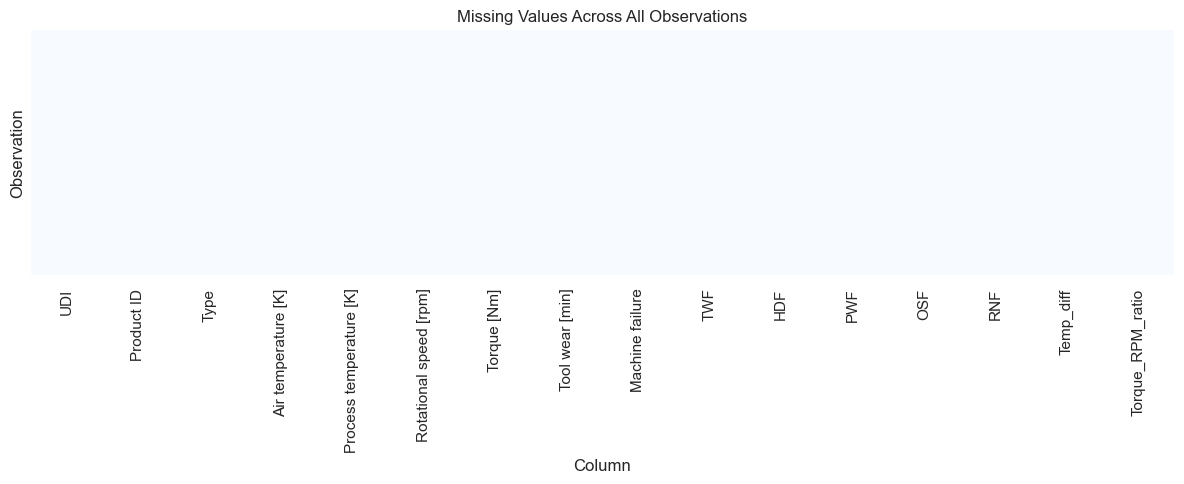

In [5]:
plt.figure(figsize=(12, 5))
sns.heatmap(df.isna(), cbar=False, yticklabels=False, cmap="Blues")
plt.title("Missing Values Across All Observations")
plt.xlabel("Column")
plt.ylabel("Observation")
save_plot("missing_values_heatmap.png")


## Target variable analysis

I compare failure and non-failure counts and calculate the failure rate. This shows whether accuracy alone would give a useful picture of model performance. I will consider precision, recall, F1, and precision–recall performance during modeling.


In [6]:
target_counts = df["Machine failure"].value_counts().reindex([0, 1], fill_value=0)
target_summary = pd.DataFrame({
    "count": target_counts,
    "percentage": target_counts / len(df) * 100,
}).rename(index={0: "No failure", 1: "Failure"})
display(target_summary.round(2))


,count,percentage
Machine failure,,
No failure,9661,96.61
Failure,339,3.39


In [7]:
failure_rate = df["Machine failure"].mean()
print(f"Failure rate: {failure_rate:.2%}")
print(f"Always predicting no failure would give {1 - failure_rate:.2%} accuracy.")
print("Compare future models using precision, recall, F1, and average precision/PR curves.")


Failure rate: 3.39%
Always predicting no failure would give 96.61% accuracy.
Compare future models using precision, recall, F1, and average precision/PR curves.


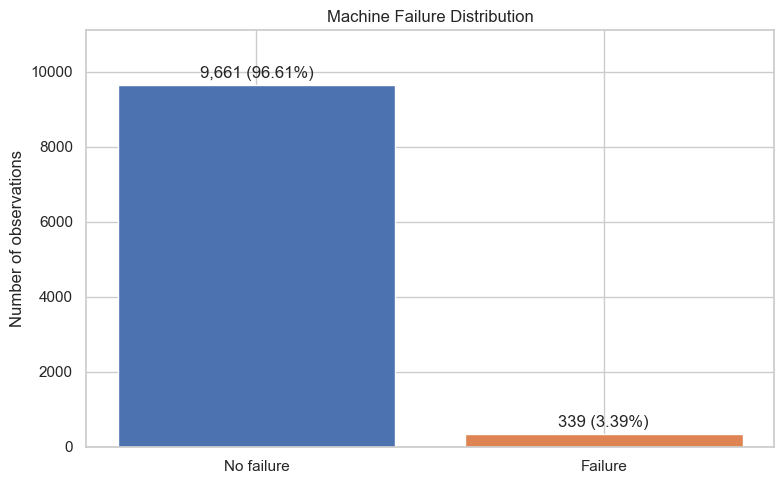

In [8]:
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(target_summary.index, target_summary["count"], color=["#4C72B0", "#DD8452"])
for bar, (label, row) in zip(bars, target_summary.iterrows()):
    ax.annotate(
        f"{int(row['count']):,} ({row['percentage']:.2f}%)",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 5), textcoords="offset points", ha="center",
    )
ax.set_ylim(0, max(target_summary["count"]) * 1.15)
ax.set_title("Machine Failure Distribution")
ax.set_ylabel("Number of observations")
save_plot("machine_failure_distribution.png")


## Failure indicator analysis

I inspect the five failure indicators:

- **TWF:** tool wear failure
- **HDF:** heat dissipation failure
- **PWF:** power failure
- **OSF:** overstrain failure
- **RNF:** random failure

I check overlapping flags and compare them with the overall `Machine failure` label. These outcome indicators are useful for analysis but will be excluded from the failure-prediction inputs.


In [9]:
failure_counts = df[failure_types].sum().astype(int)
display(pd.DataFrame({
    "flag_count": failure_counts,
    "percentage_of_all_rows": failure_counts / len(df) * 100,
}).round(2))

flag_count_per_row = df[failure_types].sum(axis=1)
any_flag = flag_count_per_row.gt(0)
target_flag_mismatch = any_flag.ne(df["Machine failure"].astype(bool))
print(f"Rows with multiple failure flags: {int(flag_count_per_row.gt(1).sum()):,}")
print(f"Rows where target differs from any failure flag: {int(target_flag_mismatch.sum()):,}")
display(pd.crosstab(
    df["Machine failure"], any_flag,
    rownames=["Machine failure"], colnames=["Any failure flag"],
))


,flag_count,percentage_of_all_rows
TWF,46,0.46
HDF,115,1.15
PWF,95,0.95
OSF,98,0.98
RNF,19,0.19


Rows with multiple failure flags: 24
Rows where target differs from any failure flag: 27


Any failure flag,False,True
Machine failure,,
0,9643,18
1,9,330


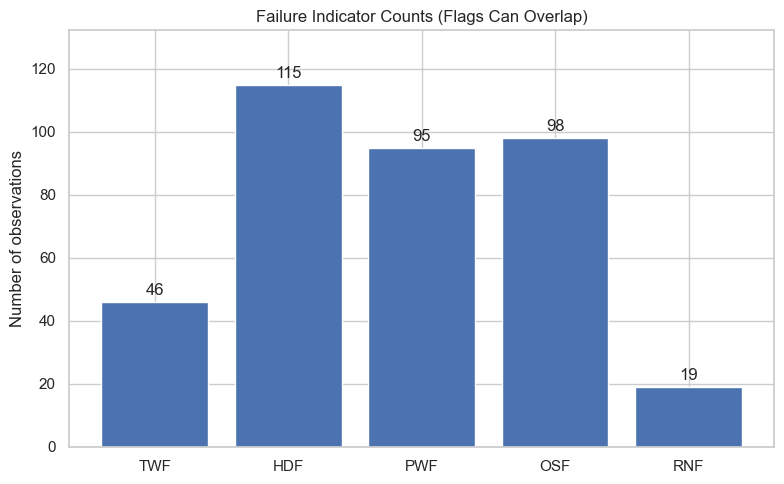

In [10]:
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(failure_counts.index, failure_counts.values, color="#4C72B0")
ax.bar_label(bars, padding=3)
ax.set_title("Failure Indicator Counts (Flags Can Overlap)")
ax.set_ylabel("Number of observations")
ax.margins(y=0.15)
save_plot("failure_type_distribution.png")


## Sensor variable distributions

I plot the distributions of air temperature, process temperature, rotational speed, torque, and tool wear. I use these charts to inspect variation, skewness, and unusual readings.


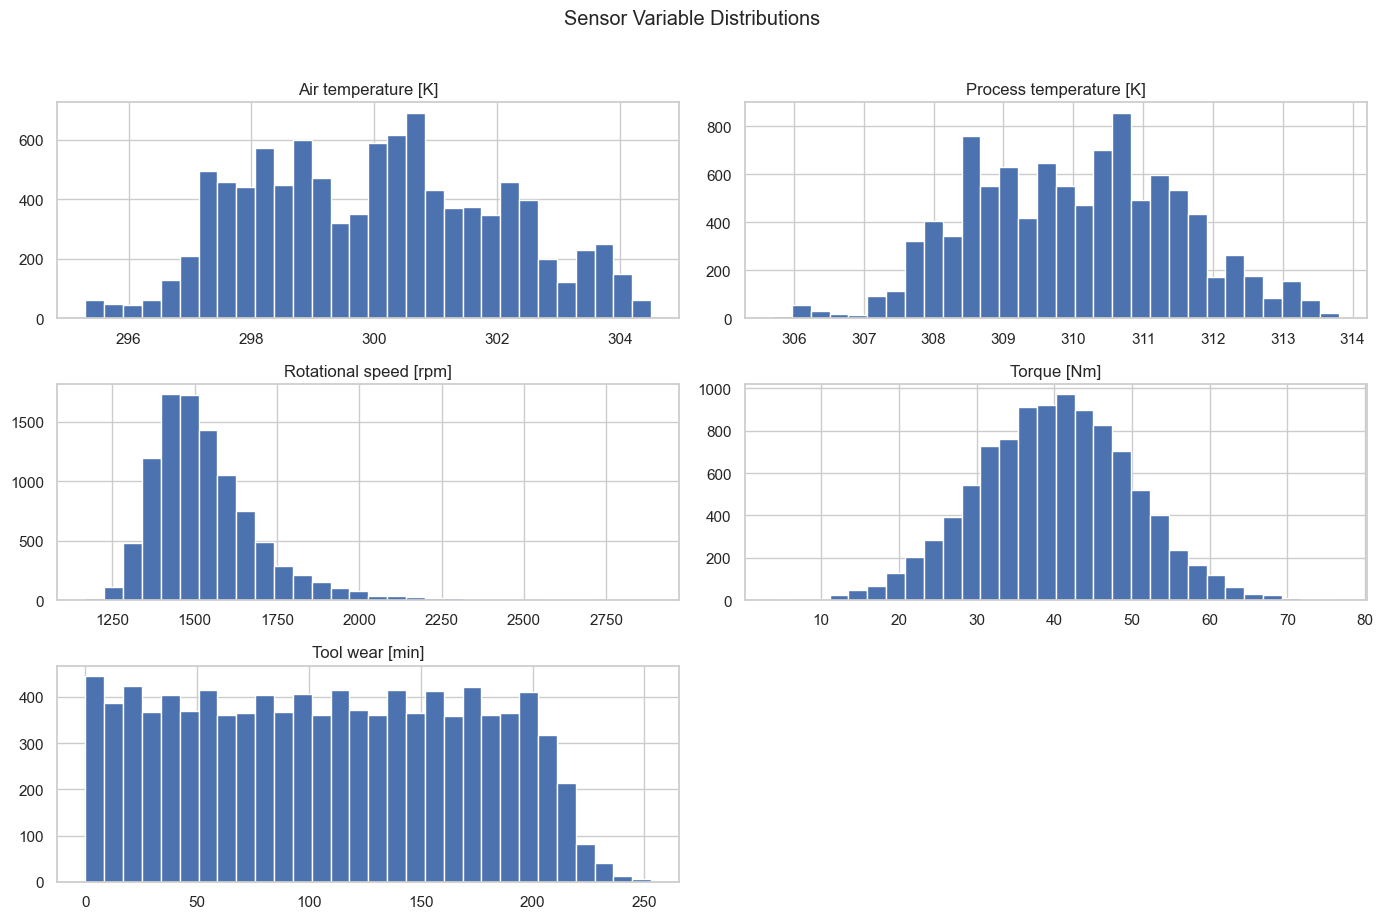

In [11]:
axes = df[sensor_features].hist(bins=30, figsize=(14, 9), color="#4C72B0", edgecolor="white")
plt.suptitle("Sensor Variable Distributions", y=1.02)
save_plot("sensor_feature_distributions.png")


## Outlier analysis

I use boxplots and the 1.5-IQR rule to identify unusual sensor values. A flagged value is not automatically a data error: it could be relevant to failure detection. I retain these observations while investigating their context.


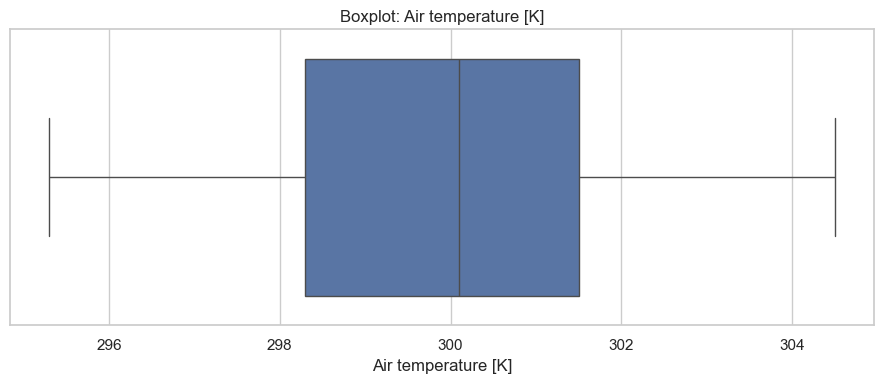

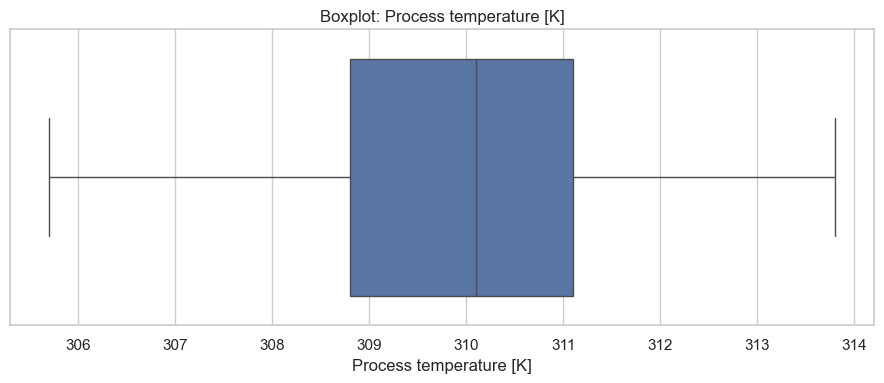

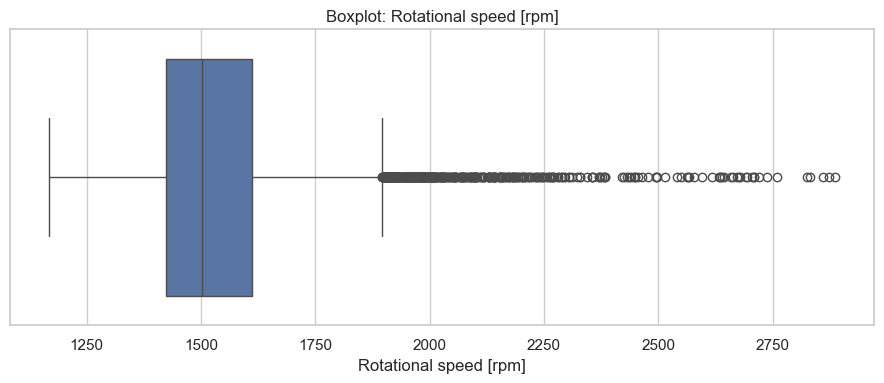

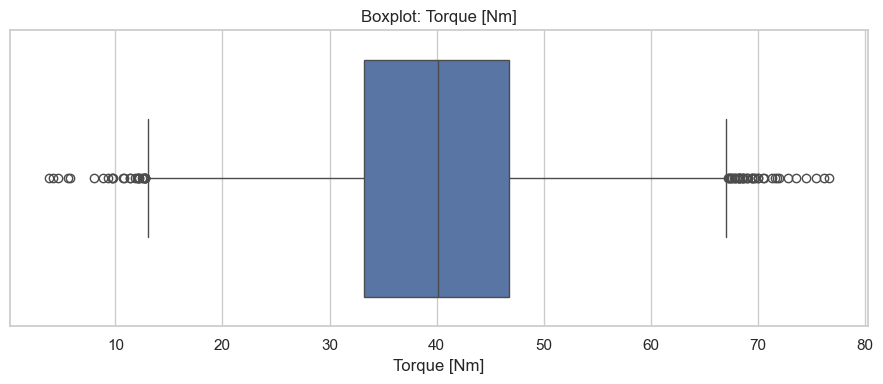

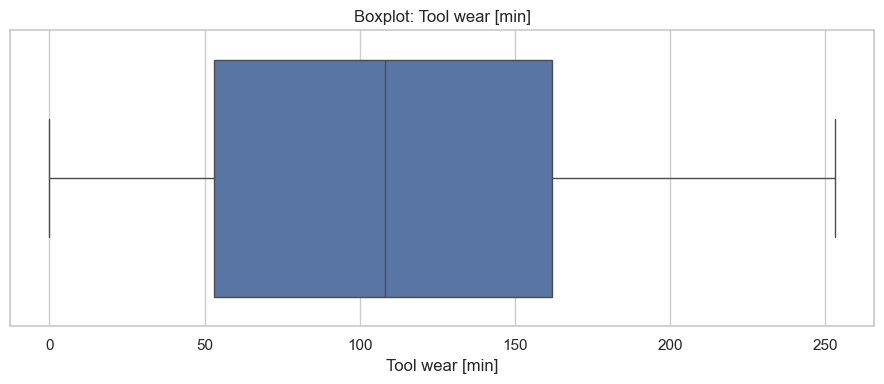

,IQR_flagged_rows,flagged_rows_with_failure
feature,,
Air temperature [K],0,0
Process temperature [K],0,0
Rotational speed [rpm],418,35
Torque [Nm],69,62
Tool wear [min],0,0


IQR flags identify unusual values, not confirmed data errors. No rows were removed.


In [12]:
outlier_rows = []
for feature in sensor_features:
    q1, q3 = df[feature].quantile([0.25, 0.75])
    iqr = q3 - q1
    outside = (df[feature] < q1 - 1.5 * iqr) | (df[feature] > q3 + 1.5 * iqr)
    outlier_rows.append({
        "feature": feature,
        "IQR_flagged_rows": int(outside.sum()),
        "flagged_rows_with_failure": int(df.loc[outside, "Machine failure"].sum()),
    })

    plt.figure(figsize=(9, 4))
    sns.boxplot(x=df[feature], color="#4C72B0")
    plt.title(f"Boxplot: {feature}")
    save_plot(f"{safe_name(feature)}_boxplot.png")

display(pd.DataFrame(outlier_rows).set_index("feature"))
print("IQR flags identify unusual values, not confirmed data errors. No rows were removed.")


## Correlation analysis

I calculate Pearson correlations for the five sensors, two derived variables, and the failure target. I exclude identifiers and failure flags from this plot.

I interpret these values as linear associations. A small correlation does not rule out a useful nonlinear relationship, and a large correlation does not establish causation.


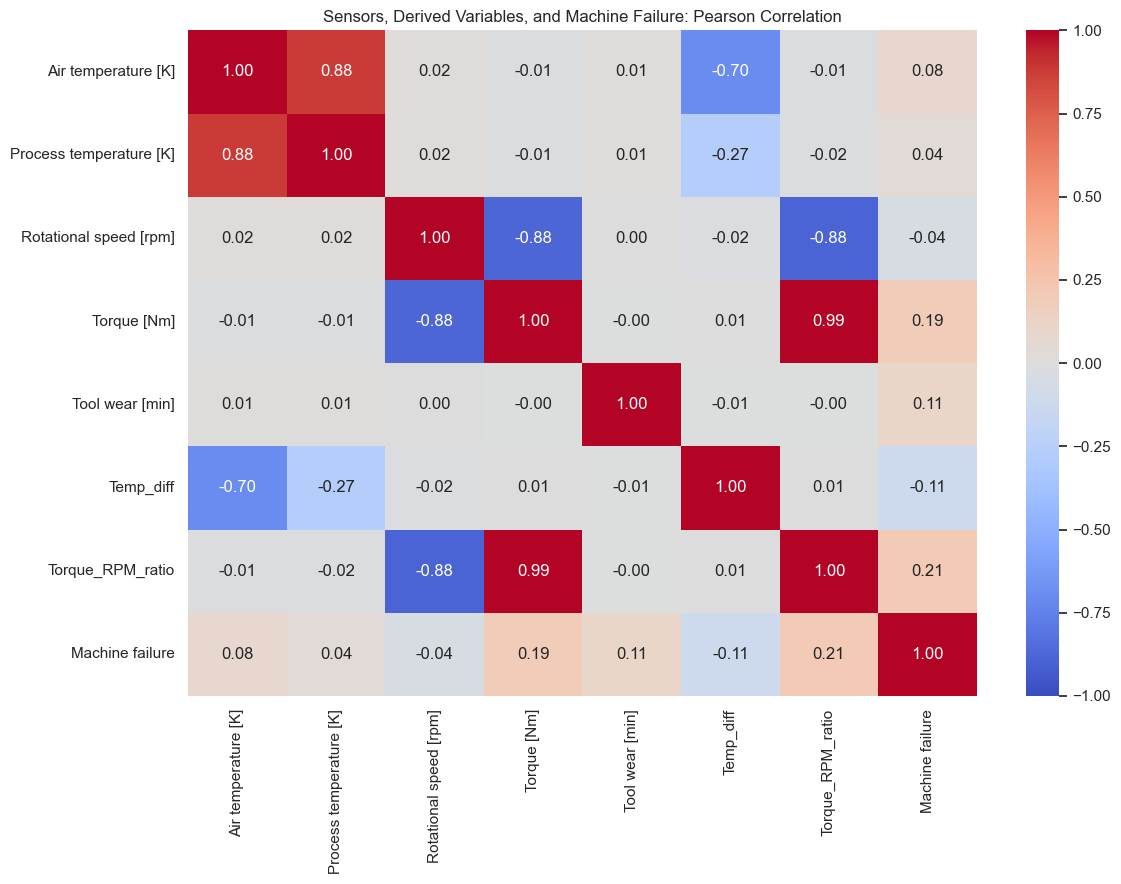

,correlation_with_failure
Air temperature [K],0.082556
Process temperature [K],0.035946
Rotational speed [rpm],-0.044188
Torque [Nm],0.191321
Tool wear [min],0.105448
Temp_diff,-0.111676
Torque_RPM_ratio,0.206480


In [13]:
analysis_features = sensor_features + ["Temp_diff", "Torque_RPM_ratio"]
corr_matrix = df[analysis_features + ["Machine failure"]].corr()

plt.figure(figsize=(12, 9))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1, center=0)
plt.title("Sensors, Derived Variables, and Machine Failure: Pearson Correlation")
save_plot("correlation_heatmap.png")

failure_correlations = corr_matrix["Machine failure"].drop("Machine failure")
display(failure_correlations.rename("correlation_with_failure").to_frame())


## Sensor readings by failure status

I compare the means, medians, and distributions of sensor readings between failed and non-failed observations. These differences help me identify candidate predictors for later evaluation.


Air temperature [K]        Process temperature [K]         \
                               mean median                    mean median   
Machine failure                                                             
0                            299.97  300.0                  310.00  310.0   
1                            300.89  301.6                  310.29  310.4   

                Rotational speed [rpm]         Torque [Nm]         \
                                  mean  median        mean median   
Machine failure                                                     
0                              1540.26  1507.0       39.63   39.9   
1                              1496.49  1365.0       50.17   53.7   

                Tool wear [min]         
                           mean median  
Machine failure                         
0                        106.69  107.0  
1                        143.78  165.0

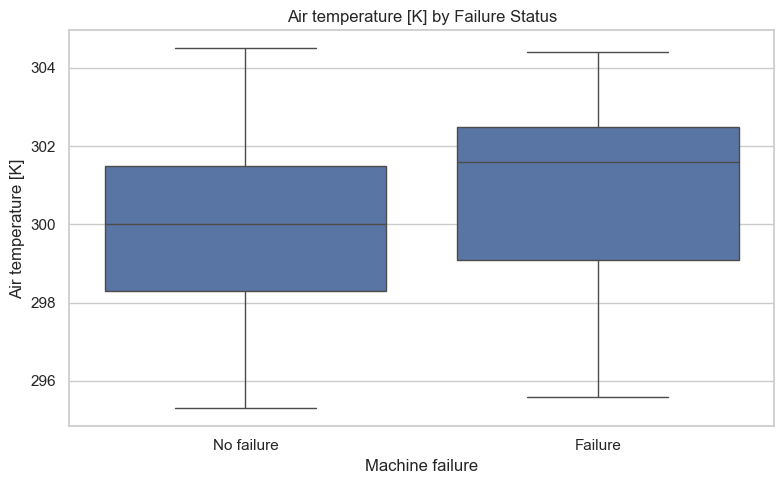

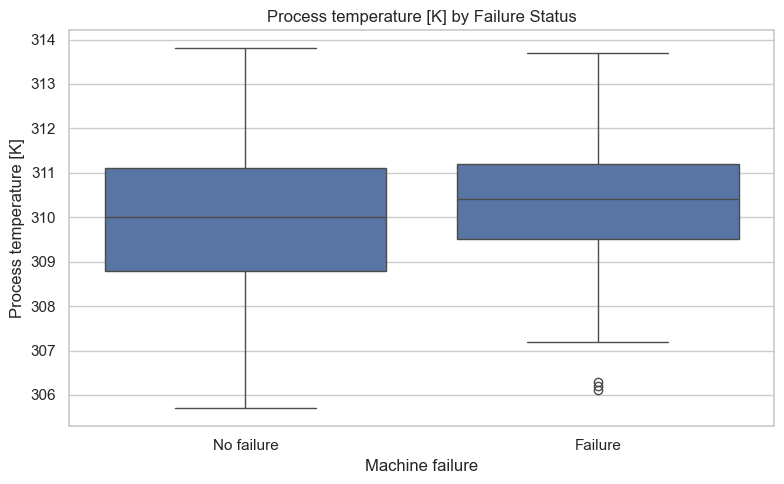

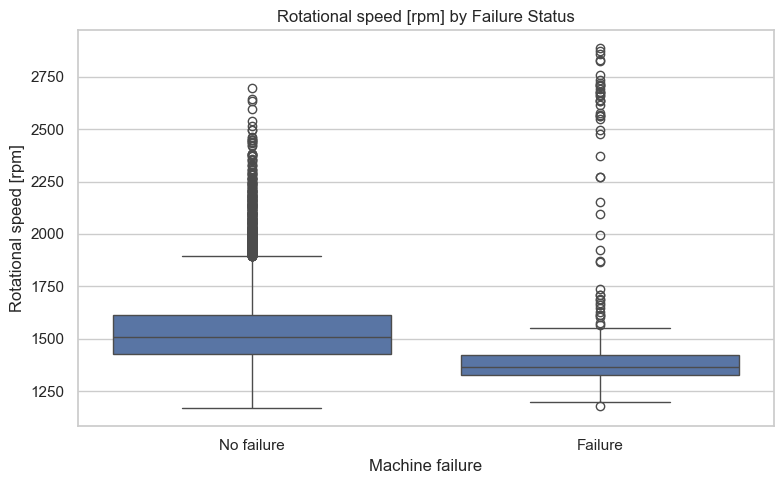

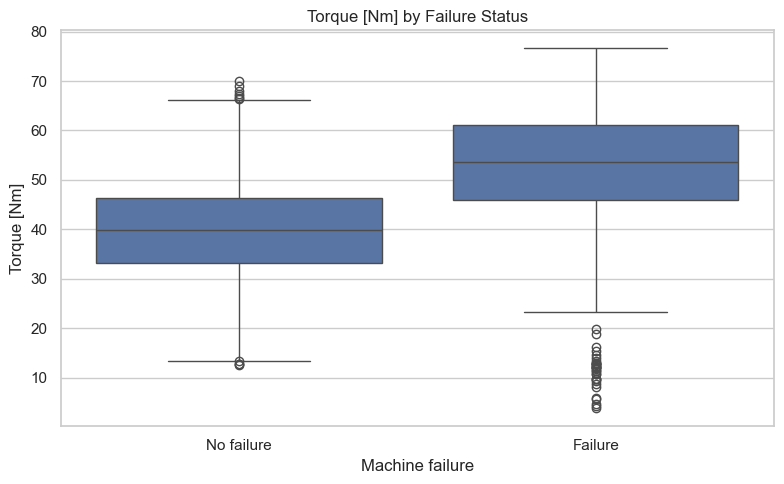

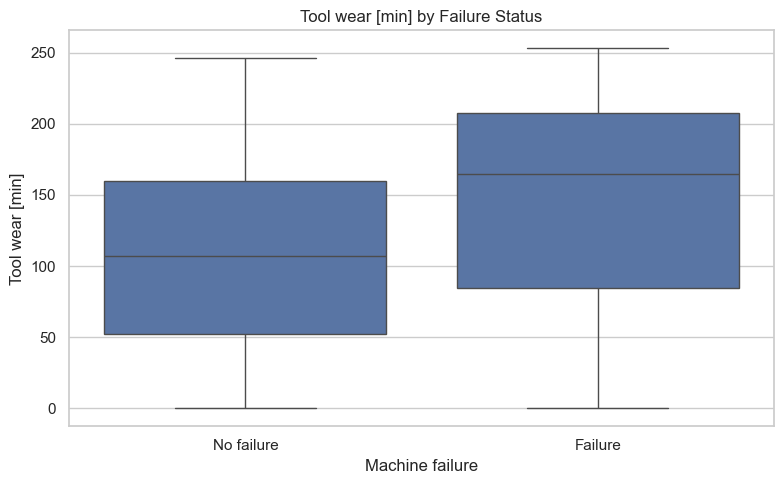

In [14]:
display(df.groupby("Machine failure")[sensor_features].agg(["mean", "median"]).round(2))

for feature in sensor_features:
    plt.figure(figsize=(8, 5))
    ax = sns.boxplot(
        x="Machine failure", y=feature, data=df, order=[0, 1],
        color="#4C72B0",
    )
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["No failure", "Failure"])
    plt.title(f"{feature} by Failure Status")
    save_plot(f"{safe_name(feature)}_vs_machine_failure.png")


## Product type and machine failure

I compare the L, M, and H product types using both observation counts and within-type failure rates. I use rates alongside counts because the groups contain different numbers of observations.


,observations,failures,failure_rate_pct
Type,,,
L,6000,235,3.92
M,2997,83,2.77
H,1003,21,2.09


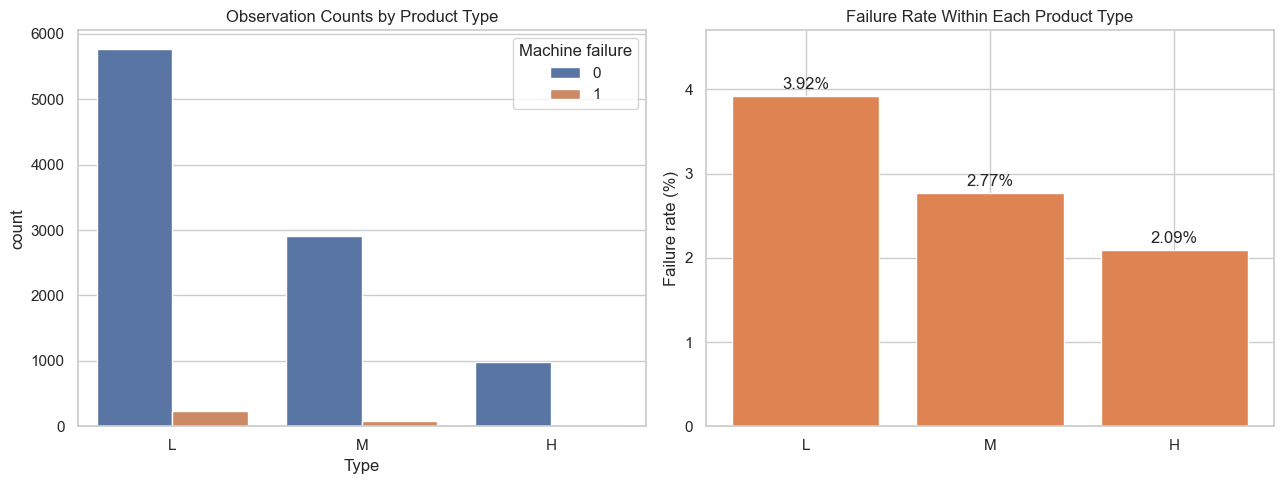

In [15]:
type_summary = (
    df.groupby("Type")["Machine failure"]
    .agg(observations="size", failures="sum", failure_rate="mean")
    .reindex(["L", "M", "H"])
)
type_summary["failure_rate_pct"] = type_summary["failure_rate"] * 100
display(type_summary[["observations", "failures", "failure_rate_pct"]].round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.countplot(
    data=df, x="Type", hue="Machine failure",
    order=["L", "M", "H"], hue_order=[0, 1], ax=axes[0],
)
axes[0].set_title("Observation Counts by Product Type")
axes[0].legend(title="Machine failure")
bars = axes[1].bar(type_summary.index, type_summary["failure_rate_pct"], color="#DD8452")
axes[1].bar_label(bars, fmt="%.2f%%", padding=3)
axes[1].set_title("Failure Rate Within Each Product Type")
axes[1].set_ylabel("Failure rate (%)")
axes[1].margins(y=0.2)
save_plot("machine_type_vs_machine_failure.png")


## Derived variables

I compare temperature difference and the torque-to-RPM ratio across failure status. Both variables are calculated from sensor readings without using the target or failure flags.


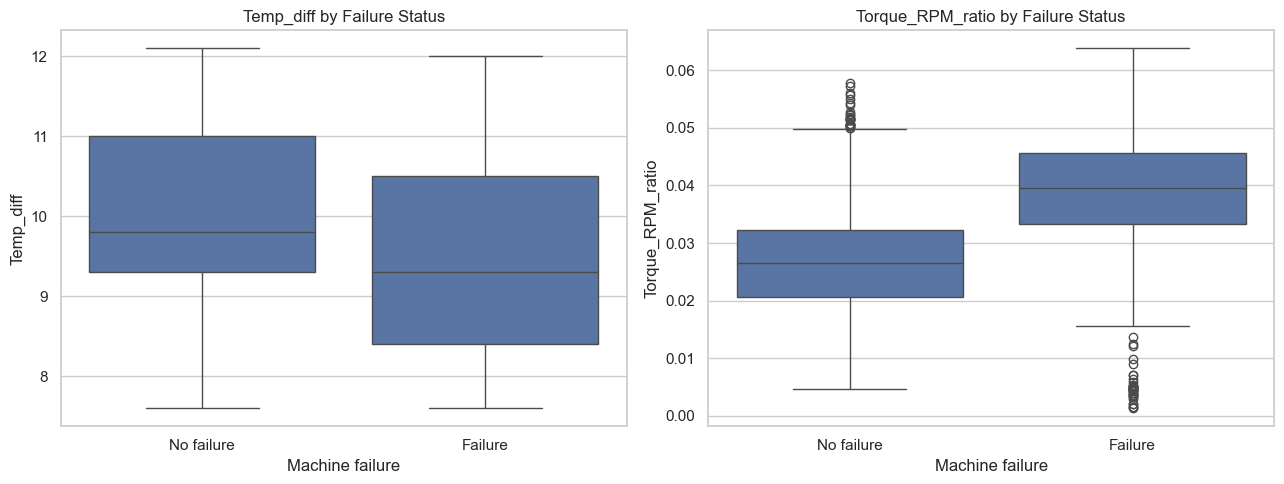

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, feature in zip(axes, ["Temp_diff", "Torque_RPM_ratio"]):
    sns.boxplot(
        data=df, x="Machine failure", y=feature,
        order=[0, 1], color="#4C72B0", ax=ax,
    )
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["No failure", "Failure"])
    ax.set_title(f"{feature} by Failure Status")
save_plot("engineered_features_vs_machine_failure.png")


## Findings and next steps

I calculate a summary from the dataset used in this run and review it alongside the charts.

- I investigate disagreements between the overall failure label and individual failure flags before choosing a cleaning policy.
- I inspect unusual sensor values before deciding whether any need correction.
- I exclude identifiers and failure flags from future model inputs.
- I use validation data for model and threshold selection and reserve a final test set for evaluation.

These exploratory findings guide the next steps; they do not establish validated prediction performance.


In [17]:
strongest_feature = failure_correlations.abs().idxmax()
print(f"Observed rows: {raw_shape[0]:,}")
print(f"Machine failures: {int(df['Machine failure'].sum()):,} ({failure_rate:.2%})")
print(f"Missing values: {int(missing_values.sum()):,}")
print(f"Exact duplicate rows: {int(df.duplicated().sum()):,}")
print(f"Target / failure-flag disagreements: {int(target_flag_mismatch.sum()):,}")
print(
    f"Largest absolute Pearson correlation with failure among the plotted inputs: "
    f"{strongest_feature} ({failure_correlations[strongest_feature]:.3f})"
)
print("\nFailure rates by product type:")
print(type_summary["failure_rate_pct"].round(2).to_string())
print(f"\nSaved chart files: {len(list(VISUALS_DIR.glob('*.png')))}")


Observed rows: 10,000
Machine failures: 339 (3.39%)
Missing values: 0
Exact duplicate rows: 0
Target / failure-flag disagreements: 27
Largest absolute Pearson correlation with failure among the plotted inputs: Torque_RPM_ratio (0.206)

Failure rates by product type:
Type
L    3.92
M    2.77
H    2.09

Saved chart files: 17


## License

```text
MIT License

Copyright (c) 2026 Faizanfarid Malek

Permission is hereby granted, free of charge, to any person obtaining a copy
of this software and associated documentation files (the "Software"), to deal
in the Software without restriction, including without limitation the rights
to use, copy, modify, merge, publish, distribute, sublicense, and/or sell
copies of the Software, and to permit persons to whom the Software is
furnished to do so, subject to the following conditions:

The above copyright notice and this permission notice shall be included in all
copies or substantial portions of the Software.

THE SOFTWARE IS PROVIDED "AS IS", WITHOUT WARRANTY OF ANY KIND, EXPRESS OR
IMPLIED, INCLUDING BUT NOT LIMITED TO THE WARRANTIES OF MERCHANTABILITY,
FITNESS FOR A PARTICULAR PURPOSE AND NONINFRINGEMENT. IN NO EVENT SHALL THE
AUTHORS OR COPYRIGHT HOLDERS BE LIABLE FOR ANY CLAIM, DAMAGES OR OTHER
LIABILITY, WHETHER IN AN ACTION OF CONTRACT, TORT OR OTHERWISE, ARISING FROM,
OUT OF OR IN CONNECTION WITH THE SOFTWARE OR THE USE OR OTHER DEALINGS IN THE
SOFTWARE.
```
